In [ ]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import CHive
import scanpy as sc
import numpy as np
import pandas as pd
import scvi
import matplotlib.pyplot as plt

scvi.settings.dl_num_workers = 0
scvi.settings.num_threads = 16

%matplotlib inline
%load_ext autoreload
%autoreload 2

### read data

MIX-Seq, a method for multiplexed transcriptional profiling of post-perturbation responses across a mixture of samples with single-cell resolution, using SNP-based computational demultiplexing of single-cell RNA-sequencing data.


To illustrate the advantages of C-HIVE’s explicit disentangling strategy, we evaluated its ability to separate shared and Idasanutlin-specific transcriptional responses within a complex cellular environment. We applied C-HIVE to a large-scale Mix-seq dataset from McFarland et al. (Nature Communications, 2020), in which responses to small-molecule and genetic perturbations were profiled across pools of over 100 cancer cell lines. This case study highlights C-HIVE’s effectiveness in addressing the challenges of contrastive analysis in heterogeneous, multi-cell-type systems.

Normalize the input data (e.g., log or library size normalization) to make it suitable for MSE loss

The dataset was preprocessed following the procedure described in the contrastiveVI manuscript, including filtering of low-quality cells and selection of highly variable genes. Normalized and log-transformed expression values are stored in adata.X.

In [2]:
### Here the data have been normalized
adata = sc.read_h5ad("/home/zhaoyu/zhaoyu_disco/project/chvgae/our/code_for_github/data/single_mcfarland_process_data.h5ad")
# sc.pp.normalize_total(adata)
# sc.pp.log1p(adata)
adata.obs_names_make_unique()
adata.obs['label'] = adata.obs['condition'].map({'Idasanutlin': 1, 'DMSO': 0})
adata

AnnData object with n_obs × n_vars = 5928 × 2000
    obs: 'cell_line', 'TP53_mutation_status', 'condition', 'label'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'gene_symbols', 'gene_id'
    uns: 'hvg', 'log1p'
    layers: 'count'

Before training, we need to inform C-HIVE which cells originate from the background (i.e., control cells) and which are target cells (i.e., perturbed).
This is indicated by the label column, where 1 denotes target cells and 0 denotes background cells.
Since we need to construct a graph for each slice, the corresponding sample ID for each cell must also be provided.

### train model

For contrastive analysis, we designated the DMSO-treated cells as the background dataset and the Idasanutlin-treated cells as the target

In [3]:
layer=3
scvi.settings.seed = 42
CHive.model.CHive.setup_anndata(adata, design=['label'])
model = CHive.model.CHive(adata, n_layer=layer, design="label", knn=8, gene_graph=True)
model.train(accelerator='gpu')

adata.obsm[f"X_CHive_BG"] = model.get_latent_representation(layer=-2)
adata.obsm[f"X_CHive_Salient"] = model.get_latent_representation()

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX A6000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [17:11<00:00,  2.60s/it, v_num=1, train_loss_step=164, train_loss_epoch=161]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [17:11<00:00,  2.58s/it, v_num=1, train_loss_step=164, train_loss_epoch=161]


The X_CHive_BG, called the background variables, are shared across background and target cells. 
The X_CHive_Salient, called the salient variables, are only active in target cells and are fixed at 0 for background cells.

### clustering

Visualizing common representations, we can find that cells separate by cell types, and background dataset and target dataset are mixed well.

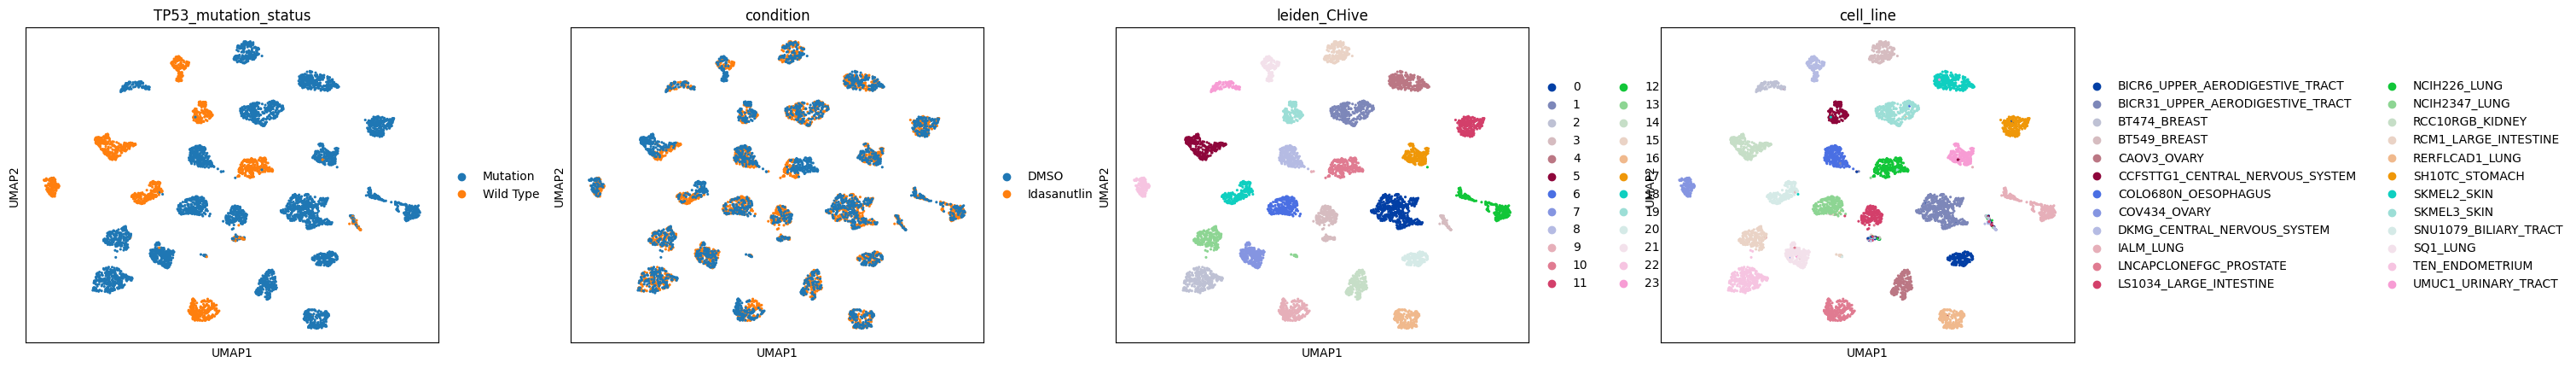

In [4]:
sc.pp.neighbors(adata, use_rep="X_CHive_BG")
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.1)
adata.obs["leiden_CHive"] = adata.obs["leiden"]
sc.pl.umap(adata, color=['TP53_mutation_status', 'condition', "leiden_CHive", 'cell_line'], 
                wspace=0.2, ncols=4)

Visualizing salient representations, we can find that cells are separate by perturb type,  highlighting target-specific signals.

Idasanutlin is a known activator of the p53 pathway, and its effect depends on the functional status of the TP53 gene: it induces pathway activation in TP53 wild-type cells but has minimal impact on cells with mutated or non-functional TP53. Therefore, we expected to observe a clear separation between TP53 wild-type and mutant cell lines in the salient representation space.


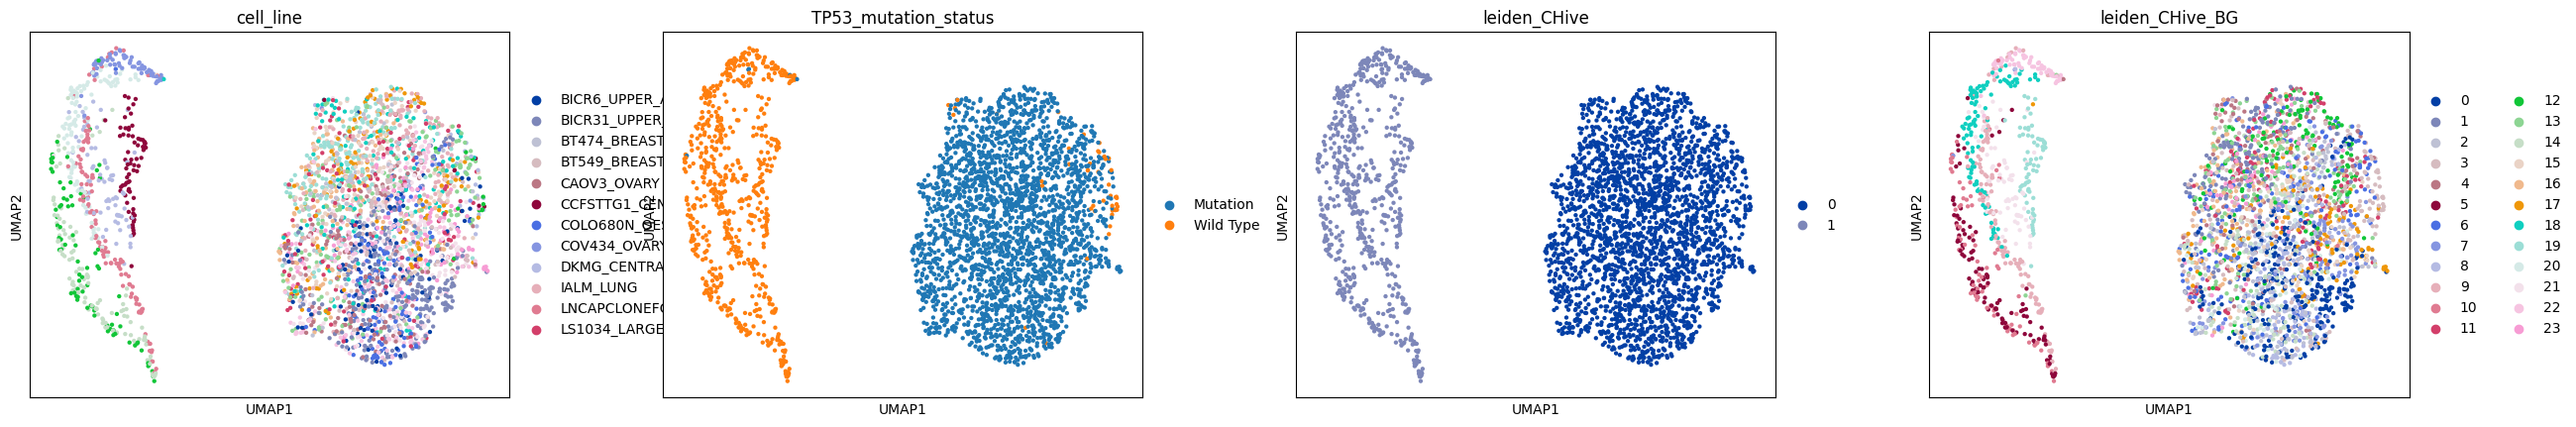

In [5]:
target_adata = adata[adata.obs.label == 1]
target_adata.obs["leiden_CHive_BG"] = adata[target_adata.obs_names, ].obs["leiden_CHive"]
sc.pp.neighbors(target_adata, use_rep="X_CHive_Salient")
sc.tl.umap(target_adata)
sc.tl.leiden(target_adata, resolution=0.1)
target_adata.obs["leiden_CHive"] = target_adata.obs["leiden"]
sc.pl.umap(target_adata, color=['cell_line', 'TP53_mutation_status', "leiden_CHive", "leiden_CHive_BG"], wspace=0.2, ncols=4)

### Interpretability

To improve interpretability, we replace the neural networks with linear functions.

In [6]:
model.module.frozen_encoder()
model.module.change_lineardecoder()
model.train(accelerator='gpu')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [10:14<00:00,  1.55s/it, v_num=1, train_loss_step=227, train_loss_epoch=222]    

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [10:14<00:00,  1.54s/it, v_num=1, train_loss_step=227, train_loss_epoch=222]


Each gene's expression can be represented as a weighted sum of several latent variables (denoted as z1, z2, ..., z10), which capture hidden patterns in the data.

Changing the value of z1, for example, will mostly affect the expression levels of genes that have large weights associated with z1 (i.e., large values in the first row of the weight matrix).

By analyzing these weights learned by the C-HIVE model, we can identify which genes are most strongly linked to each latent factor.


In [7]:
loadings = model.get_loadings()
adata.uns['loadings'] = loadings

In [8]:
loadings.head()

,Topic C1,Topic C2,Topic C3,Topic C4,Topic C5,Topic C6,Topic C7,Topic C8,Topic C9,Topic C10,Topic S1,Topic S2,Topic S3,Topic S4,Topic S5,Topic S6,Topic S7,Topic S8,Topic S9,Topic S10
gene_symbols,,,,,,,,,,,,,,,,,,,,
HES4,-0.146616,-0.069416,0.025257,-0.012220,0.053799,0.023875,-0.010147,-0.068132,0.095303,0.034644,-0.004925,0.013224,-0.010207,-0.698686,-0.174484,0.188230,0.367653,0.043868,-0.007750,-0.072777
ISG15,-0.026729,-0.066570,-0.006857,-0.088913,0.026712,0.026302,-0.039978,0.013876,0.120877,0.068728,-0.024205,0.002498,-0.005251,-0.404398,0.164451,-0.074219,-0.391355,0.120942,0.022267,-0.092495
RNF223,-0.003740,0.002362,0.000137,-0.001853,0.000797,-0.001873,0.001321,-0.004211,0.002743,0.003246,-0.001011,0.001354,-0.001279,-0.040724,-0.005703,0.023304,0.040638,0.004419,-0.000975,-0.002836
MMP23B,0.000833,-0.003220,0.007567,-0.007598,-0.000995,0.000074,0.006946,-0.001488,0.003013,0.000375,-0.000711,0.001212,0.002469,-0.028984,0.004800,-0.034914,-0.058902,0.020999,0.000282,-0.021500
TMEM52,-0.004951,-0.011671,0.002295,0.005402,-0.005201,-0.006593,0.006600,-0.009749,0.005521,0.003489,-0.014562,0.002055,0.005433,-0.025955,0.080048,-0.108624,-0.062065,0.047245,0.008277,-0.022133


We denote the i-th dimension of the common and salient embeddings as Topic Ci and Topic Si, respectively

In [9]:
prefix = "S"
loadings_salient = loadings.filter(like='Topic S')
cell_topic_salient = target_adata.obsm["X_CHive_Salient"]
rotation_results_varimax = CHive.tl.varimax(loadings_salient) 
varimax_loading = rotation_results_varimax['rotloading']
topic_salient_ratation = CHive.tl.get_rotated_scores(cell_topic_salient, rotation_results_varimax['rotmat'])
target_adata.obsm["X_CHive_Salient_rotation"] = topic_salient_ratation


In [10]:
topic_salient_ratation = pd.DataFrame(topic_salient_ratation, 
                                      columns=['Topic '+prefix+str(i) 
                                               for i in range(1, topic_salient_ratation.shape[1]+1)], 
                                      index=target_adata.obs_names)

In [11]:
t_stat_matrix, result =  CHive.tl.t_stat(topic_salient_ratation, target_adata.obs["leiden_CHive"])
result

,Label,Topic,Tvalue
0,0,Topic S5,-48.588482
1,1,Topic S5,48.588482


In [12]:
t_stat_matrix.index = ["Cluster S" + str(int(i) + 1) for i in t_stat_matrix.index]

By performing t-tests between cluster labels and topics in the salient space, we found that Topic S5 was most significantly associated with distinguishing TP53 wild-type from mutant cell lines 

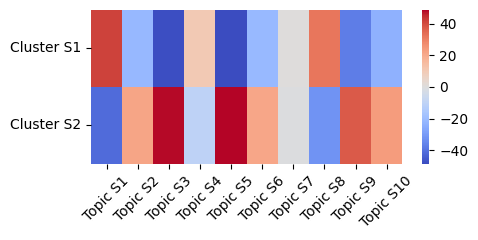

<Axes: >

In [13]:
plt.figure(figsize=(5, 2.5))
CHive.pl.t_stat_heatmap(t_stat_matrix)

In [14]:

loadings_salient_corrected, ranked_genes =  CHive.tl.correct_loadings(varimax_loading, t_stat_matrix, 
                                                                      priority_cluster="Cluster S2")
loadings_salient_corrected.head()

gene_symbols,HES4,ISG15,RNF223,MMP23B,TMEM52,CFAP74,GABRD,ENSG00000272449,TNFRSF14,MMEL1,...,TFF3,TFF2,TFF1,CBS,CSTB,ENSG00000224930,COL6A1,ENSG00000226115,COL6A2,S100B
Topic S1,0.006644,0.021439,0.001187,0.000397,0.012170,0.002187,-0.000263,0.017223,-0.000055,0.002368,...,0.002638,0.004011,0.000538,0.002035,-0.025628,0.004285,0.017015,0.001352,0.003239,0.010655
Topic S2,0.005752,-0.000024,0.000705,0.000980,0.003299,0.001911,0.001670,0.000744,0.001105,0.000901,...,-0.010399,-0.008369,-0.016652,0.007052,-0.018558,0.006102,0.020601,0.000763,0.014546,0.008919
Topic S3,-0.008737,0.009207,-0.001117,0.003138,0.009673,0.000981,0.001990,0.000463,0.004704,0.003297,...,-0.002980,0.002394,0.000887,0.018439,0.026396,-0.002349,-0.009277,-0.000757,0.001708,-0.020980
Topic S4,0.542097,0.396526,0.027723,0.041605,0.081901,0.021680,0.014724,0.038012,0.318279,0.000868,...,-0.050420,-0.025677,0.078230,0.411248,1.039051,0.035566,-0.536664,-0.046235,-0.728429,0.634419
Topic S5,-0.229766,0.127190,-0.008473,0.002774,0.077926,0.007008,0.007279,0.009529,0.034846,0.002700,...,-0.057283,-0.018197,-0.022449,0.069825,-0.107483,-0.025146,0.044184,-0.001140,0.041750,-0.155228


We then identified the top 20 genes most strongly associated with Topic S5

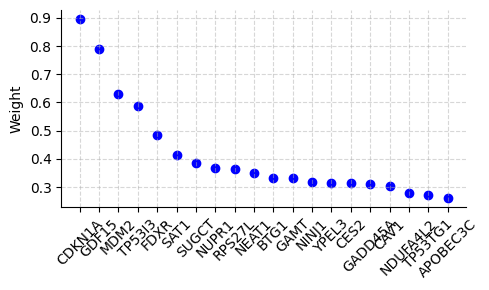

<Axes: ylabel='Weight'>

In [15]:
plt.figure(figsize=(5, 3))
CHive.pl.topic_genes(loadings_salient_corrected, topic_name="Topic S5", top_n=20)